In [1]:
# 02 - SVM (TP3): SVM with a linear kernel and an RBF kernel, 3 folds, metrics, and MLflow
#
# STEP 1 - data analysis of the wavs (duration, quality) + why the prof's flatten()[:1200] is false
# STEP 2 - data cleaning: remove the broken wavs
# STEP 3 - data mining: which duration (2, 5 or 10 s) gives the best SVM? (every test is saved in MLflow)
# STEP 4 - data mining on the Mel features: what is different between normal and abnormal hearts?
# STEP 5 - the final SVM results (linear + rbf), the figure, and the final models in MLflow
#
# Before running: 01_eda_data_wrangling.ipynb must have created ourdataset/train/normal/ and abnormal/,
# and the MLflow container must be running (docker start mlflow-server)

In [2]:
import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold            # to cut the dataset in 3 folds
from sklearn.preprocessing import StandardScaler     # to put all the features on the same scale
from sklearn.decomposition import PCA                # data mining: see the features in 2D
from sklearn.svm import SVC                          # the SVM classifier
from sklearn.pipeline import make_pipeline           # the scaler + the SVM in one object (final model)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

import mlflow
import mlflow.sklearn

In [3]:
# my folders (the same as in 01)
project_folder = "D:/MLOps_Project/"                        # the .data files are saved here
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"


def load_data(file_name):
    with open(file_name, "rb") as f:    # "rb" = read binary
        return pickle.load(f)           # gives back what we saved


def save_data(data, file_name):
    with open(file_name, "wb") as f:    # "wb" = write binary
        pickle.dump(data, f)


# MLflow (Service 6): our server = the Docker container "mlflow-server", on port 5000
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("audio_benchmark")    # ONE experiment for the 5 models of the project

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1790783986045, experiment_id='1', last_update_time=1790783986045, lifecycle_stage='active', name='audio_benchmark', tags={}>

In [4]:
# ==================== STEP 1 - Data analysis of the wavs (before making any feature) ====================
SR = 2000    # every wav is read at 2000 Hz (the sample rate of PhysioNet: heart sounds are below 1000 Hz)


def wav_info(file, class_name):
    signal, rate = librosa.load(file, sr=SR)
    return {
        "file": file,
        "class": class_name,
        "label": 1 if class_name == "abnormal" else 0,
        "duration": len(signal) / rate,                               # in seconds
        "peak": np.max(np.abs(signal)),                               # the loudest sample (1 = the maximum): ~0 = no sound
        "clipping_pct": 100 * np.mean(np.abs(signal) >= 0.99),        # % of saturated samples (sound too loud)
    }


rows = []
for class_name in ["abnormal", "normal"]:
    for file in glob(ourdataset_folder + class_name + "/*.wav"):
        rows.append(wav_info(file, class_name))

wavs_info = pd.DataFrame(rows)    # a table: 1 row per wav
print(len(wavs_info), "wavs")
ipd.display(wavs_info.groupby("class")[["duration", "peak", "clipping_pct"]].agg(["min", "median", "max"]).round(3))

3766 wavs


duration                    peak               clipping_pct         \
              min  median      max    min median    max          min median   
class                                                                         
abnormal    0.857  20.724  121.998  0.023  0.917  1.196          0.0    0.0   
normal      0.764  18.606  101.673  0.019  0.856  1.465          0.0    0.0   

                  
             max  
class             
abnormal   9.025  
normal    10.926

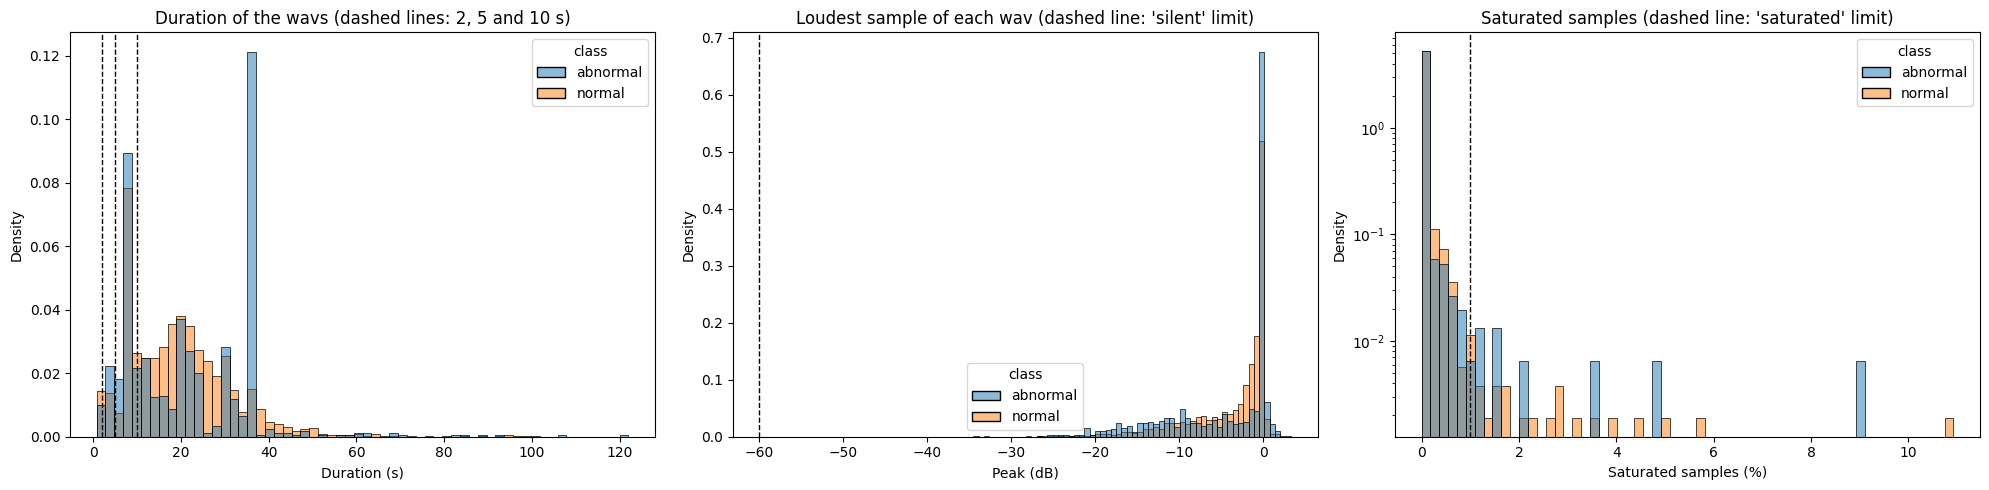

Broken wavs found by each rule:


,too_short,silent,saturated
class,,,
abnormal,5,0,9
normal,50,0,22


In [5]:
# the rules for a "broken" wav (you can change these numbers)
MIN_DURATION = 2       # seconds: less than ~2 heartbeats
MIN_PEAK = 0.001       # almost no sound at all (-60 dB)
MAX_CLIPPING = 1       # more than 1% of the samples are saturated

wavs_info["too_short"] = wavs_info["duration"] < MIN_DURATION
wavs_info["silent"] = wavs_info["peak"] < MIN_PEAK
wavs_info["saturated"] = wavs_info["clipping_pct"] > MAX_CLIPPING
wavs_info["peak_db"] = 20 * np.log10(np.maximum(wavs_info["peak"], 1e-6))    # the peak in dB (0 dB = the maximum)

# ONE figure: the duration, the loudness and the saturation of the wavs, normal vs abnormal
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
sns.histplot(data=wavs_info, x="duration", hue="class", bins=60, stat="density", common_norm=False)
for seconds in [2, 5, 10]:
    plt.axvline(seconds, color="black", linestyle="--", linewidth=1)
plt.title("Duration of the wavs (dashed lines: 2, 5 and 10 s)")
plt.xlabel("Duration (s)")

plt.subplot(1, 3, 2)
sns.histplot(data=wavs_info, x="peak_db", hue="class", bins=60, stat="density", common_norm=False)
plt.axvline(20 * np.log10(MIN_PEAK), color="black", linestyle="--", linewidth=1)
plt.title("Loudest sample of each wav (dashed line: 'silent' limit)")
plt.xlabel("Peak (dB)")

plt.subplot(1, 3, 3)
sns.histplot(data=wavs_info, x="clipping_pct", hue="class", bins=60, stat="density", common_norm=False)
plt.axvline(MAX_CLIPPING, color="black", linestyle="--", linewidth=1)
plt.yscale("log")
plt.title("Saturated samples (dashed line: 'saturated' limit)")
plt.xlabel("Saturated samples (%)")

plt.tight_layout()
plt.show()

print("Broken wavs found by each rule:")
ipd.display(wavs_info.groupby("class")[["too_short", "silent", "saturated"]].sum())

30.0 s -> table of 128 bands x 1292 moments -> the 1200 numbers = 0.9 band(s)
0.8 s -> table of 128 bands x 33 moments -> the 1200 numbers = 36.4 band(s)


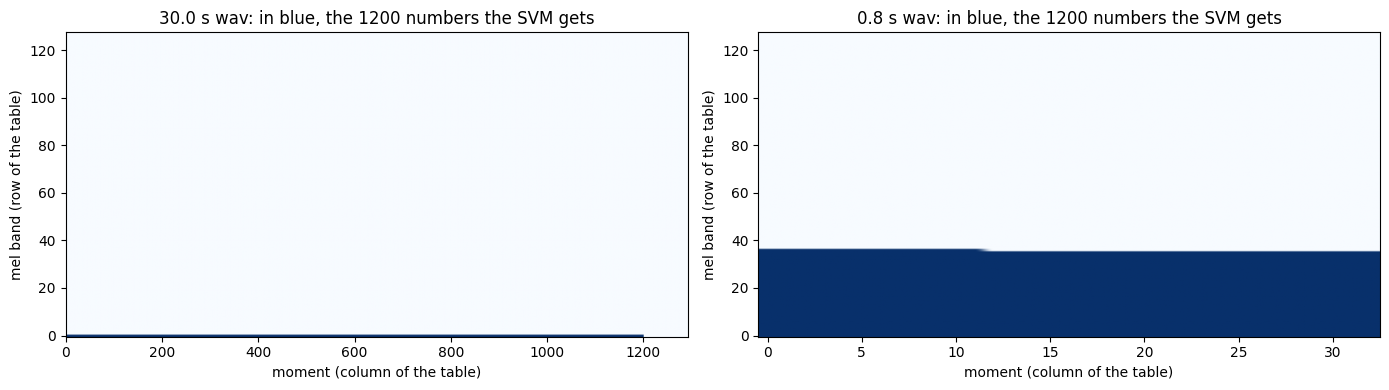

In [6]:
# What is inside the prof's flatten()[:1200]? (his Mel spectrogram: 22050 Hz, 128 bands)
def prof_mel(file):
    signal, rate = librosa.load(file)
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=2048, hop_length=512, n_mels=128)
    return librosa.power_to_db(S, ref=np.max)


long_index = np.argmin(np.abs(wavs_info["duration"] - 30))    # a wav of about 30 seconds
short_index = np.argmin(wavs_info["duration"])                 # the shortest wav

plt.figure(figsize=(14, 4))
place = 1
for index in [long_index, short_index]:
    file = wavs_info["file"][index]
    duration = wavs_info["duration"][index]
    S_DB = prof_mel(file)                     # a table: 128 bands x 1 column per moment
    used = np.zeros(S_DB.size)
    used[:1200] = 1                           # flatten()[:1200] = the first 1200 numbers, read band after band
    used = used.reshape(S_DB.shape)           # put them back in the table to see WHERE they are
    print("{:.1f} s -> table of {} bands x {} moments -> the 1200 numbers = {:.1f} band(s)".format(
        duration, S_DB.shape[0], S_DB.shape[1], 1200 / S_DB.shape[1]))

    plt.subplot(1, 2, place)
    plt.imshow(used, aspect="auto", origin="lower", cmap="Blues")
    plt.title("{:.1f} s wav: in blue, the 1200 numbers the SVM gets".format(duration))
    plt.xlabel("moment (column of the table)")
    plt.ylabel("mel band (row of the table)")
    place = place + 1

plt.tight_layout()
plt.show()
# -> for a long wav the 1200 numbers are ONLY the lowest band (murmurs are in higher bands), for a short wav
#    they are many bands: number 500 does not mean the same thing for 2 wavs -> false.
#    Correction (STEP 3): the same duration and the same sample rate for every wav

In [7]:
# ==================== STEP 2 - Data cleaning: remove the broken wavs ====================
# the SAME rules for normal and abnormal (decided without looking at the class),
# so later the audio engine can check a new wav with the same rules
bad = wavs_info["too_short"] | wavs_info["silent"] | wavs_info["saturated"]
clean = wavs_info[~bad].reset_index(drop=True)    # ~ = "not": we keep the wavs that are NOT bad

print("removed:", bad.sum(), "wavs ->", wavs_info[bad]["class"].value_counts().to_dict())
print("kept:", len(clean), "wavs -> normal:", (clean["label"] == 0).sum(), "| abnormal:", (clean["label"] == 1).sum())

removed: 85 wavs -> {'normal': 71, 'abnormal': 14}
kept: 3681 wavs -> normal: 2855 | abnormal: 826


In [8]:
# ==================== The features: the Mel spectrogram of EACH wav (corrected version of the prof's) ====================
#   1. every wav at 2000 Hz
#   2. every wav = exactly the same duration: the middle part (the start is often noisy, when the
#      stethoscope is placed); a shorter wav is repeated until it is long enough
#   3. Mel spectrogram: 30 bands, windows of 256 samples (0.128 s) -> a table of 30 bands x N moments
#   4. flatten() -> number i = the SAME band at the SAME moment for every wav
N_MELS = 30
N_FFT = 256
HOP_LENGTH = 256


def get_mel_features(file, seconds):
    n_samples = SR * seconds
    signal, rate = librosa.load(file, sr=SR)

    if len(signal) < n_samples:
        repeat = int(np.ceil(n_samples / len(signal)))
        signal = np.tile(signal, repeat)[:n_samples]       # too short: repeat the heartbeats
    else:
        start = (len(signal) - n_samples) // 2
        signal = signal[start:start + n_samples]           # too long: keep the middle part

    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS)
    S_DB = librosa.power_to_db(S, ref=np.max)    # a table of 30 bands x N moments, in dB
    return S_DB.flatten()


def build_features(seconds):
    X = []
    for file in clean["file"]:               # only the clean wavs
        X.append(get_mel_features(file, seconds))
    return np.array(X), clean["label"].values

In [9]:
# The 3 folds, with the example of the TP: 10 wavs numbered 1 to 10
# each fold: 1 third of the wavs = test (33%), the 2 other thirds = train (66%)
# each fold takes a DIFFERENT third for the test -> every wav is tested exactly once
def show_folds(kfold, items):
    fold = 1
    for train_index, test_index in kfold.split(items):
        print("  Fold", fold, ": test =", items[test_index], "  train =", items[train_index])
        fold = fold + 1


items = np.arange(1, 11)    # [ 1  2  3  4  5  6  7  8  9 10]

print("In order (like the example of the TP):")
show_folds(KFold(n_splits=3), items)
# 10 can't be cut in 3 equal parts, so the first test has 4 wavs (then wav 10 is tested too)

print("At random (random1 # random2: a different random third each time):")
show_folds(KFold(n_splits=3, shuffle=True, random_state=1), items)

In order (like the example of the TP):
  Fold 1 : test = [1 2 3 4]   train = [ 5  6  7  8  9 10]
  Fold 2 : test = [5 6 7]   train = [ 1  2  3  4  8  9 10]
  Fold 3 : test = [ 8  9 10]   train = [1 2 3 4 5 6 7]
At random (random1 # random2: a different random third each time):
  Fold 1 : test = [ 3  5  7 10]   train = [1 2 4 6 8 9]
  Fold 2 : test = [1 2 4]   train = [ 3  5  6  7  8  9 10]
  Fold 3 : test = [6 8 9]   train = [ 1  2  3  4  5  7 10]


In [10]:
# The TP3 method in ONE function: 3 folds, and for each fold: split -> scale -> train the SVM -> predict -> metrics
kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the SAME 3 random folds every time (fair comparison)


def evaluate_svm(X, y, kernel):
    folds = []
    fold = 1
    for train_index, test_index in kfold.split(X):
        # 1. split: 2 thirds of the wavs to train (66%), 1 third to test (33%)
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        # 2. same scale for every feature (mean 0, std 1), learned on the TRAIN only:
        #    the test wavs stay "never seen"
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # 3. train the SVM, then ask it the class of the test wavs
        #    class_weight="balanced": 3.5x more normal wavs than abnormal ones, so a mistake on an
        #    abnormal wav counts 3.5x more (if not, the SVM says "normal" too often)
        model = SVC(kernel=kernel, class_weight="balanced")
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # 4. metrics (precision, recall, f1: for the abnormal class)
        folds.append({
            "fold": fold,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),
            "recall": recall_score(y_test, y_pred),
            "f1": f1_score(y_test, y_pred),
            "y_test": y_test,      # kept to show the details in STEP 5
            "y_pred": y_pred,
        })
        fold = fold + 1
    return folds

In [11]:
# ==================== STEP 3 - Which duration is the best? (data mining) ====================
# For 2, 5 and 10 seconds: make the features, test the SVM (2 kernels x 3 folds), save the test in MLflow.
# It takes several minutes.
durations_to_test = [2, 5, 10]
kernels = ["linear", "rbf"]

features = {}       # the features of each duration (to reuse them after)
results = []        # 1 line per (duration, kernel, fold)
predictions = {}    # the predictions of each fold, for STEP 5
run_ids = {}        # the MLflow run of each (duration, kernel), to add the final model in STEP 5

for seconds in durations_to_test:
    X, y = build_features(seconds)
    features[seconds] = (X, y)
    print(seconds, "s ->", X.shape[1], "features per wav (", N_MELS, "bands x", X.shape[1] // N_MELS, "moments )")

    for kernel in kernels:
        folds = evaluate_svm(X, y, kernel)
        predictions[(seconds, kernel)] = folds
        for f in folds:
            results.append({"seconds": seconds, "kernel": kernel, "fold": f["fold"], "accuracy": f["accuracy"],
                            "precision": f["precision"], "recall": f["recall"], "f1": f["f1"]})

        # 1 MLflow run per (duration, kernel)
        with mlflow.start_run(run_name="svm_" + kernel + "_" + str(seconds) + "s") as run:
            mlflow.log_param("model", "SVM")
            mlflow.log_param("kernel", kernel)
            mlflow.log_param("class_weight", "balanced")
            mlflow.log_param("n_folds", 3)
            mlflow.log_param("features", "mel spectrogram flatten (30 bands)")
            mlflow.log_param("seconds", seconds)
            mlflow.log_param("sample_rate", SR)
            mlflow.log_param("n_features", X.shape[1])
            mlflow.log_param("n_wavs", len(y))
            for metric in ["accuracy", "precision", "recall", "f1"]:
                mlflow.log_metric("mean_" + metric, np.mean([f[metric] for f in folds]))
            for f in folds:
                mlflow.log_metric("fold_accuracy", f["accuracy"], step=f["fold"])
                mlflow.log_metric("fold_recall", f["recall"], step=f["fold"])
            run_ids[(seconds, kernel)] = run.info.run_id

table = pd.DataFrame(results)
summary = table.groupby(["seconds", "kernel"])[["accuracy", "precision", "recall", "f1"]].mean().round(3)
print("Mean of the 3 folds:")
ipd.display(summary)

# the best duration = the highest F1 of abnormal. F1 balances the recall (find the sick hearts) and the
# precision (not too many false alarms): with the recall alone, a model that says "abnormal" too often would win
best = summary["f1"].idxmax()              # (seconds, kernel)
best_seconds = best[0]
print("Best duration:", best_seconds, "s (F1", summary.loc[best, "f1"], "| recall", summary.loc[best, "recall"],
      "with the", best[1], "kernel)")

# recall and F1 of each duration, linear vs rbf
plt.figure(figsize=(12, 4))
x = np.arange(len(durations_to_test))
for place, metric in [(1, "recall"), (2, "f1")]:
    plt.subplot(1, 2, place)
    plt.bar(x - 0.2, [summary.loc[(s, "linear"), metric] for s in durations_to_test], width=0.4, label="linear")
    plt.bar(x + 0.2, [summary.loc[(s, "rbf"), metric] for s in durations_to_test], width=0.4, label="rbf")
    plt.xticks(x, [str(s) + " s" for s in durations_to_test])
    plt.ylim(0, 1)
    plt.title("Mean " + metric + " of the 3 folds")
    plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

2 s -> 480 features per wav ( 30 bands x 16 moments )


MlflowException: API request to http://localhost:5000/api/2.0/mlflow/runs/create failed with exception HTTPConnectionPool(host='localhost', port=5000): Max retries exceeded with url: /api/2.0/mlflow/runs/create (Caused by NewConnectionError("HTTPConnection(host='localhost', port=5000): Failed to establish a new connection: [WinError 10061] Aucune connexion n’a pu être établie car l’ordinateur cible l’a expressément refusée"))

In [ ]:
# the features of the best duration, saved like the prof (a = the features, b = the classes)
X, y = features[best_seconds]
save_data(list(X), project_folder + "mel_features_svm_a.data")
save_data(list(y), project_folder + "mel_features_svm_b.data")
print("X:", X.shape, "->", X.shape[0], "wavs,", X.shape[1], "features | normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))

In [ ]:
# ==================== STEP 4 - Data mining: what is different between normal and abnormal hearts? ====================
M = X.reshape(len(X), N_MELS, -1)               # back to tables: wavs x 30 bands x N moments
mean_normal = M[y == 0].mean(axis=0)            # the average table of the normal wavs
mean_abnormal = M[y == 1].mean(axis=0)          # the average table of the abnormal wavs
difference = mean_abnormal - mean_normal        # > 0 (red): louder in the abnormal hearts

# the center frequency (Hz) of each of the 30 mel bands
band_freqs = librosa.mel_frequencies(n_mels=N_MELS + 2, fmax=SR / 2)[1:-1]

# the "profile" of each wav = the mean of each band over time
profile = M.mean(axis=2)                        # wavs x 30 bands
profile_normal = profile[y == 0].mean(axis=0)
profile_abnormal = profile[y == 1].mean(axis=0)

# PCA: all the features of each wav summarized in 2 numbers, to see the 2 classes on a plot
X_2d = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))

# ONE figure: 2 rows x 3 columns
plt.figure(figsize=(20, 10))
extent = [0, best_seconds, 0.5, N_MELS + 0.5]   # x = seconds, y = band number

plt.subplot(2, 3, 1)
plt.imshow(mean_normal, aspect="auto", origin="lower", extent=extent, cmap="magma")
plt.colorbar(format="%+2.0f dB")
plt.title("Average Mel spectrogram: normal")
plt.xlabel("Time (s)")
plt.ylabel("Mel band")

plt.subplot(2, 3, 2)
plt.imshow(mean_abnormal, aspect="auto", origin="lower", extent=extent, cmap="magma")
plt.colorbar(format="%+2.0f dB")
plt.title("Average Mel spectrogram: abnormal")
plt.xlabel("Time (s)")
plt.ylabel("Mel band")

plt.subplot(2, 3, 3)
limit = np.abs(difference).max()
plt.imshow(difference, aspect="auto", origin="lower", extent=extent, cmap="RdBu_r", vmin=-limit, vmax=limit)
plt.colorbar(format="%+2.1f dB")
plt.title("Difference: abnormal - normal")
plt.xlabel("Time (s)")
plt.ylabel("Mel band")

plt.subplot(2, 3, (4, 5))                       # takes places 4 AND 5
for profiles, mean_profile, name, color in [(profile[y == 0], profile_normal, "normal", "tab:blue"),
                                            (profile[y == 1], profile_abnormal, "abnormal", "tab:red")]:
    std = profiles.std(axis=0)
    plt.plot(band_freqs, mean_profile, color=color, linewidth=2, label=name)
    plt.fill_between(band_freqs, mean_profile - std, mean_profile + std, color=color, alpha=0.15)
plt.title("Mean loudness of each band (line = mean, shadow = +/- std)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("dB")
plt.legend()

plt.subplot(2, 3, 6)
plt.scatter(X_2d[y == 0, 0], X_2d[y == 0, 1], s=6, alpha=0.4, color="tab:blue", label="normal")
plt.scatter(X_2d[y == 1, 0], X_2d[y == 1, 1], s=6, alpha=0.4, color="tab:red", label="abnormal")
plt.title("PCA: the features in 2D")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()

plt.tight_layout()
plt.show()

# the 5 bands where the 2 classes are the most different
band_difference = profile_abnormal - profile_normal
print("Bands where abnormal and normal hearts differ the most:")
for i in np.argsort(np.abs(band_difference))[::-1][:5]:
    print("  band {:2d} (~{:4.0f} Hz): abnormal - normal = {:+.1f} dB".format(i + 1, band_freqs[i], band_difference[i]))

In [ ]:
# ==================== STEP 5 - The final SVM results (with the best duration) ====================
final_results = []         # 1 line per (kernel, fold)
confusion_matrices = []    # for the figure

for kernel in kernels:
    print("==================== SVM with kernel =", kernel, "-", best_seconds, "s ====================")
    for f in predictions[(best_seconds, kernel)]:
        print("--- Fold", f["fold"], ": test =", len(f["y_test"]), "wavs")
        print(classification_report(f["y_test"], f["y_pred"], target_names=["normal", "abnormal"]))
        confusion_matrices.append(confusion_matrix(f["y_test"], f["y_pred"]))
        final_results.append({"kernel": kernel, "fold": f["fold"], "accuracy": f["accuracy"],
                              "precision": f["precision"], "recall": f["recall"], "f1": f["f1"]})

final_table = pd.DataFrame(final_results)
ipd.display(final_table.round(3))
print("Mean of the 3 folds (like the example: (0.7 + 0.8 + 0.9) / 3 = 0.8):")
ipd.display(final_table.groupby("kernel")[["accuracy", "precision", "recall", "f1"]].mean().round(3))

In [ ]:
def PlotConfusionMatrix(cm, title):
    # cm[i][j] = number of test wavs of class i (true) that the SVM put in class j (predicted)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"])
    plt.title(title)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")


# ONE figure: 2 rows (linear, rbf) x 4 columns (fold 1, fold 2, fold 3, accuracy)
plt.figure(figsize=(22, 9))

places = [1, 2, 3, 5, 6, 7]    # the 6 confusion matrices: linear fold 1, 2, 3, then rbf fold 1, 2, 3
for i in range(6):
    r = final_results[i]
    plt.subplot(2, 4, places[i])
    PlotConfusionMatrix(confusion_matrices[i],
                        r["kernel"] + " - Fold " + str(r["fold"]) + " - accuracy=" + str(round(r["accuracy"], 2)))

# column 4 (places 4 AND 8): the accuracy of each fold, linear vs rbf
accuracy = final_table["accuracy"].values    # 6 values: linear fold 1, 2, 3, then rbf fold 1, 2, 3
x = np.arange(3)

plt.subplot(2, 4, (4, 8))
plt.bar(x - 0.2, accuracy[0:3], width=0.4, label="linear")
plt.bar(x + 0.2, accuracy[3:6], width=0.4, label="rbf")
plt.xticks(x, ["Fold 1", "Fold 2", "Fold 3"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy of each fold: linear vs rbf (" + str(best_seconds) + " s)")
plt.legend(loc="lower right")

plt.tight_layout()
plt.savefig(project_folder + "tp3_svm_figure.png")    # also saved as an image file, to send it to MLflow
plt.show()

In [ ]:
# ==================== MLflow: add the figure and the final model to the runs of the best duration ====================
# The 3 folds were only to MEASURE the SVM. The model we keep is trained on ALL the clean wavs.
# make_pipeline = the scaler + the SVM in ONE object, so later the audio engine can use it in one step
for kernel in kernels:
    with mlflow.start_run(run_id=run_ids[(best_seconds, kernel)]):    # we open the run of STEP 3 again
        mlflow.set_tag("final", "yes")
        mlflow.log_artifact(project_folder + "tp3_svm_figure.png")
        final_model = make_pipeline(StandardScaler(), SVC(kernel=kernel, class_weight="balanced"))
        final_model.fit(X, y)
        mlflow.sklearn.log_model(final_model, "model", input_example=X[:5])

# the best kernel for the project = the highest recall on the abnormal class (the sick hearts)
mean_recall = final_table.groupby("kernel")["recall"].mean()
print(mean_recall.round(3))
print("Best model: SVM", mean_recall.idxmax(), "with", best_seconds, "s of each wav")